# Работа 4: Ансамблевая классификация данных

## 1. Формулировка задания
1. Обучить модели, выполняющие классификацию заданного набора данных с помощью одной из техник ансамблевой классификации. Параметрами являются:
   - Набор данных;
   - Ансамблевая техника (бэггинг, случайный лес или бустинг);
   - Количество участников ансамбля (n_estimators);
   - Дополнительные гиперпараметры в соответствии с выбранной техникой (глубина базовых деревьев, темп обучения, доля признаков/подвыборки и др.).
2. Провести эксперименты на наборе данных, варьируя количество участников ансамбля от 50 до 100 с шагом 10.
3. Выполнить визуализацию полученных результатов:
   - Построить графики зависимости показателей качества классификации (Accuracy, Precision, Recall, F1-score) от количества участников ансамбля;
   - Нанести на графики соответствующие эталонные значения (baseline), полученные для одиночного дерева решений в работе №3.
4. Подготовить структурированный отчёт.

## 2. Ссылка на репозиторий
Каталог репозиторий: `https://github.com/GeRoNioPLAY/Data_analysis`

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    RandomForestClassifier,
)
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 425
np.random.seed(RANDOM_STATE)

## 3. Загрузка и предварительная обработка данных

In [25]:
COLUMNS = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income",
]

NUMERIC_COLS = [
    "age",
    "fnlwgt",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
]

CATEGORICAL_COLS = [
    "workclass",
    "education",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native-country",
]

TRAIN_FILE = "../lab3/adult.data"
TEST_FILE = "../lab3/adult.test"


def load_and_preprocess_adult(train_path=TRAIN_FILE, test_path=TEST_FILE):
    df_train = pd.read_csv(
        train_path,
        names=COLUMNS,
        sep=r"\s*,\s*",
        engine="python",
        na_values="?",
        comment="|",
    )
    df_test = pd.read_csv(
        test_path,
        names=COLUMNS,
        sep=r"\s*,\s*",
        engine="python",
        na_values="?",
        comment="|",
    )
    df = pd.concat([df_train, df_test], ignore_index=True)
    df = pd.concat([df_train, df_test], ignore_index=True)

    df["income"] = (
        df["income"].astype(str).str.strip().str.replace(".", "", regex=False)
    )
    df = df[df["income"].isin(["<=50K", ">50K"])].copy()
    df.dropna(inplace=True)
    df["income"] = (df["income"] == ">50K").astype(np.int32)

    for col in NUMERIC_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df.dropna(inplace=True)

    for col in CATEGORICAL_COLS:
        df[col] = df[col].astype(str).str.strip()

    X = pd.get_dummies(
        df.drop("income", axis=1), columns=CATEGORICAL_COLS, drop_first=True
    )
    y = df["income"].copy()

    return X, y


X_full, y_full = load_and_preprocess_adult()
print(f"Размерность предобработанных данных: X={X_full.shape}, y={y_full.shape}")
print(f"Доля положительного класса (>50K): {y_full.mean():.4f}")

Размерность предобработанных данных: X=(45222, 96), y=(45222,)
Доля положительного класса (>50K): 0.2478


## 4. Разработка универсальной программы ансамблевой классификации

In [26]:
class CustomEnsembleClassifier:
    def __init__(
        self,
        technique="random_forest",
        n_estimators=100,
        max_depth=None,
        learning_rate=1.0,
        random_state=RANDOM_STATE,
    ):
        self.technique = technique.lower()
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.random_state = random_state
        self.model = self._create_model()

    def _create_model(self):
        if self.technique == "random_forest":
            return RandomForestClassifier(
                n_estimators=self.n_estimators,
                max_depth=self.max_depth,
                random_state=self.random_state,
                n_jobs=-1,
            )
        elif self.technique == "bagging":
            base_dt = DecisionTreeClassifier(
                max_depth=self.max_depth,
                random_state=self.random_state,
            )
            return BaggingClassifier(
                estimator=base_dt,
                n_estimators=self.n_estimators,
                random_state=self.random_state,
                n_jobs=-1,
            )
        elif self.technique == "boosting":
            base_dt = DecisionTreeClassifier(
                max_depth=1 if self.max_depth is None else self.max_depth,
                random_state=self.random_state,
            )
            return AdaBoostClassifier(
                estimator=base_dt,
                n_estimators=self.n_estimators,
                learning_rate=self.learning_rate,
                random_state=self.random_state,
            )
        else:
            raise ValueError(
                f"Неизвестная техника: {self.technique}. Выберите 'random_forest', 'bagging' или 'boosting'."
            )

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict(self, X):
        return self.model.predict(X)

## 5. Проведение экспериментов

In [27]:
SAMPLE_SIZE = 8000
df_sample_X = X_full.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE)
df_sample_y = y_full.loc[df_sample_X.index]

X_train, X_test, y_train, y_test = train_test_split(
    df_sample_X,
    df_sample_y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df_sample_y,
)

print(f"Обучающая выборка: {X_train.shape[0]} строк")
print(f"Тестовая выборка: {X_test.shape[0]} строк")

baseline_tree = DecisionTreeClassifier(
    max_depth=4, min_samples_split=20, random_state=RANDOM_STATE
)
baseline_tree.fit(X_train, y_train)
y_pred_base = baseline_tree.predict(X_test)

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_base),
    "Precision": precision_score(y_test, y_pred_base, zero_division=0),
    "Recall": recall_score(y_test, y_pred_base, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_base, zero_division=0),
}

print("\nПоказатели одного дерева решений (baseline)")
for m_name, m_val in baseline_metrics.items():
    print(f"{m_name}: {m_val:.4f}")

n_estimators_list = [50, 60, 70, 80, 90, 100]
ensemble_techniques = ["random_forest", "bagging", "boosting"]

results = []

for tech in ensemble_techniques:
    for n_est in n_estimators_list:
        clf = CustomEnsembleClassifier(
            technique=tech,
            n_estimators=n_est,
            max_depth=8 if tech != "boosting" else 1,
            random_state=RANDOM_STATE,
        )
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)

        results.append(
            {
                "Техника": tech,
                "n_estimators": n_est,
                "Accuracy": acc,
                "Precision": prec,
                "Recall": rec,
                "F1-Score": f1,
            }
        )

df_results = pd.DataFrame(results)
display(df_results.sort_values(by=["Техника", "n_estimators"]))

Обучающая выборка: 6400 строк
Тестовая выборка: 1600 строк

Показатели одного дерева решений (baseline)
Accuracy: 0.8444
Precision: 0.7765
Recall: 0.5190
F1-Score: 0.6222


,Техника,n_estimators,Accuracy,Precision,Recall,F1-Score
6,bagging,50,0.857500,0.783051,0.584810,0.669565
7,bagging,60,0.858750,0.788396,0.584810,0.671512
8,bagging,70,0.857500,0.783051,0.584810,0.669565
9,bagging,80,0.858125,0.781879,0.589873,0.672439
10,bagging,90,0.858750,0.784512,0.589873,0.673410
11,bagging,100,0.857500,0.781145,0.587342,0.670520
12,boosting,50,0.853750,0.792727,0.551899,0.650746
13,boosting,60,0.854375,0.771812,0.582278,0.663781
14,boosting,70,0.854375,0.775510,0.577215,0.661829
15,boosting,80,0.853750,0.772881,0.577215,0.660870


## 6. Визуализация показателей качества классификации

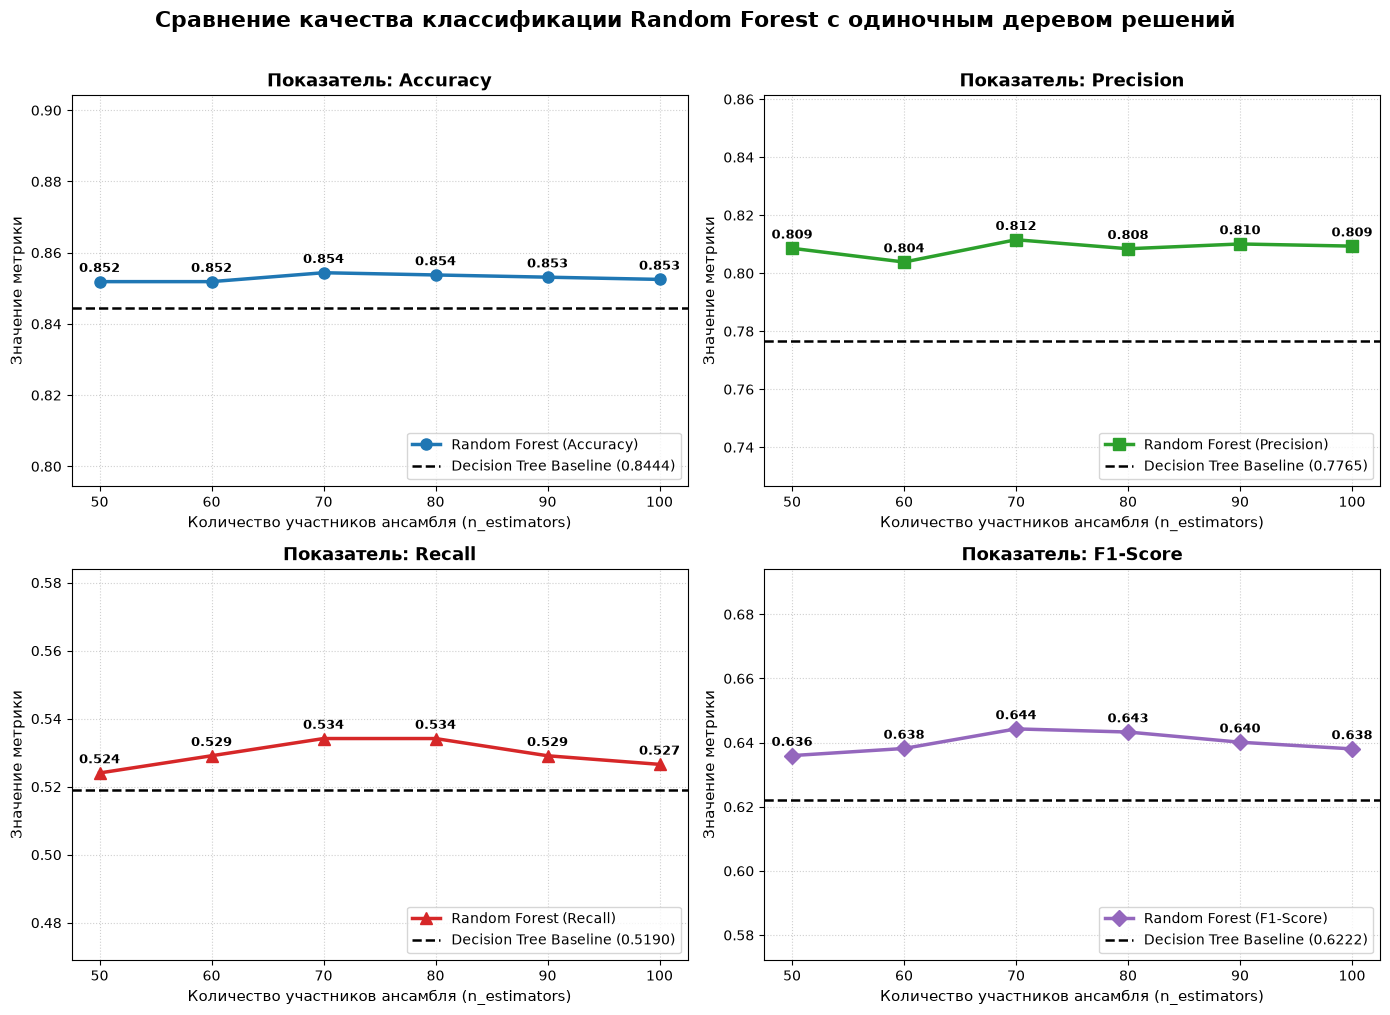

In [28]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
colors = {
    "Accuracy": "#1f77b4",
    "Precision": "#2ca02c",
    "Recall": "#d62728",
    "F1-Score": "#9467bd",
}
markers = {"Accuracy": "o", "Precision": "s", "Recall": "^", "F1-Score": "D"}

df_rf = df_results[df_results["Техника"] == "random_forest"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]
    ax.plot(
        df_rf["n_estimators"],
        df_rf[metric],
        color=colors[metric],
        marker=markers[metric],
        linewidth=2.5,
        markersize=8,
        label=f"Random Forest ({metric})",
    )
    base_val = baseline_metrics[metric]
    ax.axhline(
        base_val,
        color="black",
        linestyle="--",
        linewidth=1.8,
        label=f"Decision Tree Baseline ({base_val:.4f})",
    )

    for x_val, y_val in zip(df_rf["n_estimators"], df_rf[metric]):
        ax.annotate(
            f"{y_val:.3f}",
            (x_val, y_val),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=9,
            fontweight="bold",
        )

    ax.set_title(f"Показатель: {metric}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Количество участников ансамбля (n_estimators)", fontsize=11)
    ax.set_ylabel("Значение метрики", fontsize=11)
    ax.set_xticks(n_estimators_list)
    ax.set_ylim(
        min(df_rf[metric].min(), base_val) - 0.05,
        max(df_rf[metric].max(), base_val) + 0.05,
    )
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="lower right", fontsize=10)

plt.suptitle(
    "Сравнение качества классификации Random Forest с одиночным деревом решений",
    fontsize=16,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

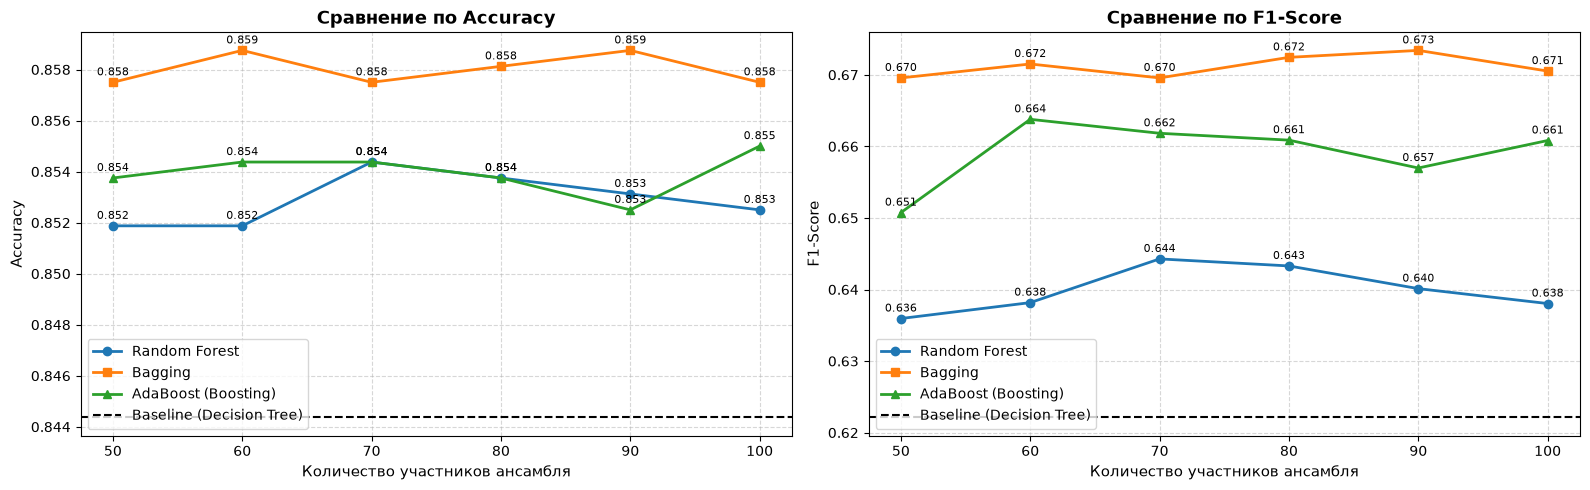

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

tech_styles = {
    "random_forest": ("#1f77b4", "o", "Random Forest"),
    "bagging": ("#ff7f0e", "s", "Bagging"),
    "boosting": ("#2ca02c", "^", "AdaBoost (Boosting)"),
}

for tech, (col, mark, label_name) in tech_styles.items():
    df_t = df_results[df_results["Техника"] == tech]
    ax1.plot(
        df_t["n_estimators"],
        df_t["Accuracy"],
        color=col,
        marker=mark,
        linewidth=2,
        label=label_name,
    )
    ax2.plot(
        df_t["n_estimators"],
        df_t["F1-Score"],
        color=col,
        marker=mark,
        linewidth=2,
        label=label_name,
    )

    for x, y in zip(df_t["n_estimators"], df_t["Accuracy"]):
        ax1.annotate(
            f"{y:.3f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 5),
            ha="center",
            fontsize=8,
        )

    for x, y in zip(df_t["n_estimators"], df_t["F1-Score"]):
        ax2.annotate(
            f"{y:.3f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 5),
            ha="center",
            fontsize=8,
        )

ax1.axhline(
    baseline_metrics["Accuracy"],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Baseline (Decision Tree)",
)
ax2.axhline(
    baseline_metrics["F1-Score"],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Baseline (Decision Tree)",
)

ax1.set_title("Сравнение по Accuracy", fontsize=13, fontweight="bold")
ax1.set_xlabel("Количество участников ансамбля", fontsize=11)
ax1.set_ylabel("Accuracy", fontsize=11)
ax1.set_xticks(n_estimators_list)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(fontsize=10)

ax2.set_title("Сравнение по F1-Score", fontsize=13, fontweight="bold")
ax2.set_xlabel("Количество участников ансамбля", fontsize=11)
ax2.set_ylabel("F1-Score", fontsize=11)
ax2.set_xticks(n_estimators_list)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()

## 7. Пояснения и выводы

1. Все ансамблевые техники превзошли одиночное дерево решений по всем метрикам: Accuracy выросла с 84.4% до 85.2–85.9%, а F1-score — с 62.2% до 64.4%-67.3.
2. Наилучшее общее качество показал Bagging, второе место занял AdaBoost, а Random Forest третий по F1-Score.
3. Качество выходит уже при 60–80 деревьях (пик у Random Forest на 70 деревьях: F1 = 0.644); дальнейшее увеличение до 100 не дает практического прироста.